
K = 1000
Accuracy : 0.7571
Precision: 0.7697892177221218
Recall   : 0.7571
F1 Score : 0.7578036920511965

K = 3000
Accuracy : 0.723
Precision: 0.7361034378273389
Recall   : 0.723
F1 Score : 0.7227780227628812

K = 5000
Accuracy : 0.6955
Precision: 0.7087464955841974
Recall   : 0.6955
F1 Score : 0.6935628559519182

K = 7000
Accuracy : 0.67
Precision: 0.6841434494625981
Recall   : 0.67
F1 Score : 0.6657475049502779

K = 9000
Accuracy : 0.6414
Precision: 0.6576833346626477
Recall   : 0.6414
F1 Score : 0.6331126102988058

Results Summary
      K  Accuracy  Precision  Recall  F1 Score
0  1000    0.7571   0.769789  0.7571  0.757804
1  3000    0.7230   0.736103  0.7230  0.722778
2  5000    0.6955   0.708746  0.6955  0.693563
3  7000    0.6700   0.684143  0.6700  0.665748
4  9000    0.6414   0.657683  0.6414  0.633113


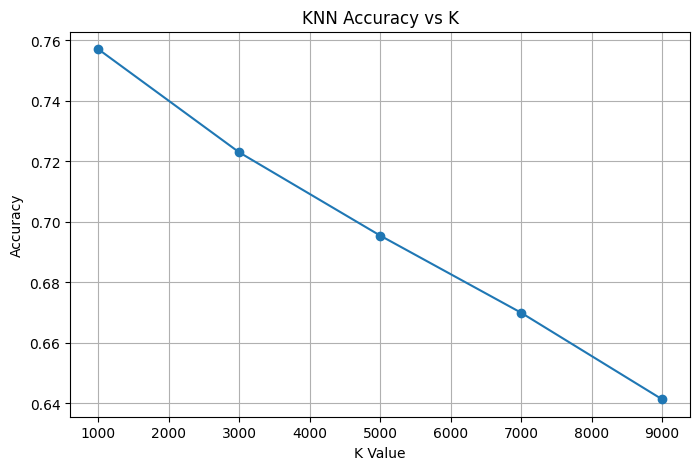

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# Load Fashion MNIST Dataset
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Preprocessing

# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

# Flatten images
X_train = X_train.reshape(len(X_train), -1)
X_test = X_test.reshape(len(X_test), -1)

# Experiment with Different K Values
k_values = [1000, 3000, 5000, 7000, 9000]
results = []

for k in k_values:

    # Create KNN model
    knn = KNeighborsClassifier(n_neighbors=k)

    # Train model
    knn.fit(X_train, y_train)

    # Prediction
    y_pred = knn.predict(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average='weighted'
    )

    recall = recall_score(
        y_test,
        y_pred,
        average='weighted'
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted'
    )

    # Store results
    results.append(
        [k, accuracy, precision, recall, f1]
    )

    # Print results for each K
    print(f"\nK = {k}")
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)


# Results Table
results_df = pd.DataFrame(
    results,
    columns=[
        'K',
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ]
)

print("\nResults Summary")
print(results_df)


# Accuracy Plot
plt.figure(figsize=(8, 5))

plt.plot(
    results_df['K'],
    results_df['Accuracy'],
    marker='o'
)

plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs K")
plt.grid(True)
plt.show()